**Introduction to the Pade Transform (PT)**

The Pade Transform is an effective way of decomposing a signal into a sum of damped exponentials, called *resonances*. The Fast Pade Transform (FPT) is -like the Fast Fourier Transform- a way of speeding this up to $\mathcal{O}(n \log{n})$. There are certain features of the PT that make it uniquely suited to specific tasks, such as noise/artefact detection, and dealing with truncated signals. But how does the Pade Transform work?

Let us consider a signal which is the sum of many damped complex exponentials: $$\mathcal{S}(t) = \sum_{k=1}^{N} A_k \exp{(i {\theta}_{k})} \exp{(- \lambda_k + i 2 \pi f_k t)}$$ 

Where each contribution to the overall signal is offset by it's own amplitude $A_k$, phase $\theta_k$, frequency $f_k$, and decay rate $- \lambda_k$. When we read this signal into a computer, we do not record continuous $t$, and instead record the signal at lots of discrete points. If $t_n = n \Delta t$, then at each data point $n$ the signal is: $$\mathcal{S}_n = \sum_{k=1}^{N} A_k \exp{(i {\theta}_{k})} \exp{(- \lambda_k + i 2 \pi f_k) n\Delta t}$$ 

Let us define $\mathcal{z}_k = e^{(-\lambda_k + i 2 \pi f_k) \Delta t}$ and $d_k = A_k e^{i \theta_k}$ so that our signal can be written more concisely as: $$\mathcal{S}_n = \sum_{k=1}^{N} d_k \mathcal{z}_k^{n}$$

The basic job of the Pade Transform is to see $\mathcal{S_1}, \mathcal{S_2},\mathcal{S_3}, ...$ and try to infer $\mathcal{z}(k), d(k)$. Let's get an idea of what these signals, and their constituent elements are like.

/home/awp509-admin/miniconda3/envs/metabolabpy/lib/python3.11/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/home/awp509-admin/miniconda3/envs/metabolabpy/lib/python3.11/site-packages/matplotlib/cbook.py:1407: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


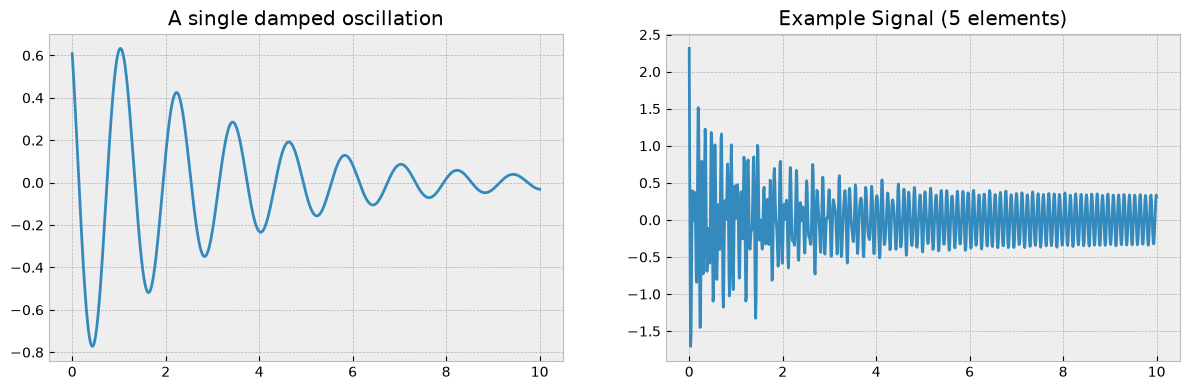

In [1]:
from numpy import random as rnd
import numpy as np
from matplotlib import pyplot as plt

tmax = 1000
delta_t = 0.01
time = np.linspace(0, tmax * delta_t, tmax)

def signal(k, n, delta_t=0.01):
    """
    Returns a snapshot of an oscillation with random elements for a given k
    """

    j = complex(0, 1)
    
    rnd.seed(k)
    amp, decay, phase = rnd.rand(3)
    freq = 20 * rnd.rand()

    d_k = amp * np.exp(j*phase)
    z_k = np.exp((-decay + (j*2*np.pi*freq)) * n * delta_t)

    return d_k * z_k

def generate_fid_element(k, T=tmax):
    """
    Generates the full damped oscillation for a given set of random values
    """
    
    fid = []

    for n in range(0, T):
        fid.append(signal(k, n))

    return fid

def generate_example_fid(elements=5, T=tmax):
    """
    Collates many of these signals together to show what an ideal FID may look like
    """

    example_fid = np.zeros(tmax, dtype=complex)

    for element in range(0, elements):
        example_fid = np.add(example_fid, generate_fid_element(k=element))
        
        
    return example_fid

time = np.linspace(0, tmax * delta_t, tmax)
plt.style.use('bmh')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(time, generate_fid_element(k=6))
ax1.set_title(f"A single damped oscillation")

ax2.plot(time, generate_example_fid(elements = 5))
ax2.set_title(f"Example Signal (5 elements)")


plt.tight_layout()
fig.subplots_adjust(wspace=0.2)

plt.show()    

**How does the Pade Transform work?**

The aim of the Pade Transform is then to reconstruct the constituent elements of the FID. We now have our FID signal. How do we decompose this into it's exponentials? We start with the signal: $$\mathcal{S}_n = \sum_{k=1}^{N} d_k \mathcal{z}_k^{n}$$ This is a difficult (*non-linear*) problem as the unknown $\mathcal{z}_k$ sits in an exponent. It would be a lot nicer if the terms we wanted to find were instead the coefficients of some polynomial. In this vein we introduce some generating function $$\mathcal{G}(w) = \sum_{n=0}^{\infty} \mathcal{S}_n w^n$$ and substitute in our expression $$\mathcal{G}(w) = \sum_{k= 1}^N d_k \sum_{n = 0}^{\infty} (\mathcal{z}_k w)^n $$ But this second half is a geometric sequence! We know that for a geometric sequence $$1 + x + x^2 + x^3 + ... = \frac{1}{1-x}$$ So our expression for the generating sequence becomes: $$\mathcal{G}(w) = \sum_{k=1}^N \frac{d_k}{1 - \mathcal{z}_k w}$$

This is a rational function of the form $$\mathcal{G}(w) = \frac{\mathcal{P}(w)}{\mathcal{Q}(w)}$$
Where $$\mathcal{Q}(w) = \prod_{k = 1}^N (1 - \mathcal{z}_k w)$$

The information we want - the $\mathcal{z}_k$- is contained in the roots of the denominator. 

Our generating function $\mathcal{G}(w)$ has $k$ poles at $w = \frac{1}{\mathcal{z}_k}$ 


**How do we find $\mathcal{Q}(w)$?**

We don't know what $\mathcal{Q}(w)$ is, but we do know it must obey the equation: $\mathcal{Q(w)} \times \mathcal{G}(w) = \mathcal{P}(w)$. Let's imagine we have $K$ resonances. In that case we find that $$\mathcal{Q}(w) = 1 + q_1 w + q_2 w^2 + ... + q_K w^K$$ And we already know $$\mathcal{G}(w) = \mathcal{S}_0 + \mathcal{S}_1 w + \mathcal{S}_2 w^2 + ...$$ Multiplying these two sequences together we get: $$ \mathcal{P}(w) = (1 + q_1 w + q_2 w^2 + ...) (\mathcal{S}_0 + \mathcal{S}_1 w + \mathcal{S}_2 w^2 + ...)$$
While $n \leq K$, the co-efficient of each $w^n$ is:
$$\mathcal{S}_n + \mathcal{S}_{n-1}q_1 + \mathcal{S}_{n-2}q_2 + ... + S_{n-K} q_K$$
Now the trick. We know the polynomial, and therefore $\mathcal{P}(w)$ have finitely many terms, whilst the generating function has an infinite number of terms. This tells us that when $n \geq K$ every co-efficient must go to zero. Mathematically then, $$\mathcal{S}_n + \mathcal{S}_{n-1} q_1 + ... + S_{n-K} q_K = 0$$

This is a solvable, linear system. Each point of the FID gives us a value for $S_n$. With $K$ independent equations, we can solve the equation with $K$ unkowns. As we need $K$ equations, but our $=0$ case only holds for $n \geq K$ the noise free case would require $2K - 1$ data points.


So the full pipeline becomes: $$\operatorname{Signal} \rightarrow \{ q_1, q_2, ..., q_k \} \rightarrow \mathcal{Q}(w) \rightarrow \mathcal{z}_k \rightarrow d_k$$

Let's construct this linear system using our noise free example of 20 signals. As this is made up of 20 signals, we should be able to reconstruct this from only the first 40 datapoints. This is a powerful feature of the Pade transform. Once we have the system of $k$ equations with $k$ unknowns, it is reasonably simple to solve for ${q_k}$, and reconstruct $\mathcal{Q}(w)$

In [2]:
exponentials = 5
layered_signal = generate_example_fid(elements=exponentials)

def generate_linear_equations(k, k_signal, svd=False):
    """
    Takes the first 2k points of a signal and returns the matrix equation that defines the q_k as numpy matrices
    """

    datapoints = k_signal[:2*k].tolist()
    empty_matrix = []
    rhs_vector = []

    for i in range(k):
        matrix_row = datapoints[i:k+i]
        matrix_row.reverse()
        empty_matrix.append(matrix_row)
        rhs_vector.append( -1 * datapoints[k+i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)
    
    return matrix, rhs_vector

def solve_linear_equations(k, k_signal):
    """
    Solves the linear equations, returning the z_k
    """

    A, b = generate_linear_equations(k, k_signal)
    q_k = np.linalg.solve(A, b)

    coefficients = np.append(q_k[::-1], 1)
    roots = np.roots(coefficients)

    z_k = [(1 / root) for root in roots]

    return z_k

z_k = solve_linear_equations(exponentials, layered_signal)

print(f"{len(z_k)} roots found ")

5 roots found 


**Reconstructing the Initial Parameters**

Ok! So from our signal, using only $1\%$ of the datapoints, we have recovered the $\mathcal{z}_k$. Recall that $$\mathcal{z}_k = e^{(-\lambda_k + i 2 \pi f_k) \Delta t}$$
$$\mathcal{z}_k =\underbrace{e^{-\lambda_k \Delta t}}_{\operatorname{magnitude}} \underbrace{e^{i 2 \pi f_k \Delta t}}_{\operatorname{phase}}$$

From this, we can calculate for each of the damped exponentials that made up our signal, the phase and magnitude. With this simple test, we can recover: $$\lambda_k = - \frac{\operatorname{ln} \lvert \mathcal{z}_k \rvert}{\Delta t}, \hspace{10mm} f_k = \frac{\operatorname{arg}\mathcal{z}_k}{2 \pi \Delta t}$$ 

In [3]:
def decay_and_freq(z_k, delta_t):
    """
    Takes the complex z_k and time interval and returns the corresponding linewidths and frequency
    """

    mag = np.abs(z_k)
    arg = np.angle(z_k, deg=False)

    lambda_k = - (np.log(mag)) / delta_t
    freq_k = arg / (2*np.pi*delta_t)

    return lambda_k, freq_k


Amazing! The final step now is to reconstruct the $d_k$ so that we can reconstruct the signal and directly compare. 

From $\mathcal{S}_n = \sum_{k=1}^{N} d_k \mathcal{z}_k^{n}$ we get: $$\mathcal{S}_0 = d_1 + d_2 + d_3 + ...$$
$$\mathcal{S}_1 = d_1\mathcal{z}_1 +  d_2\mathcal{z}_2 + d_3\mathcal{z}_3 + ...$$
$$\mathcal{S}_2 = d_1\mathcal{z}_1^2 + d_2\mathcal{z}_2^2 + d_3\mathcal{z}_3^2 + ...$$

And we now have the $\mathcal{S}_n$, and the $\mathcal{z}_k$. 

This reduces to another linear algebra problem

In [4]:
def generate_more_linear_equations(k_signal, z_k):
    """
    From the signal and the z_k we generate the linear equations for the d_k
    """

    empty_matrix = []
    rhs_vector = []

    for i in range(len(z_k)):
        matrix_row = [z**i for z in z_k]
        empty_matrix.append(matrix_row)
        rhs_vector.append(k_signal[i])

    matrix = np.array(empty_matrix, dtype=complex)
    rhs_vector = np.array(rhs_vector, dtype=complex)
    
    return matrix, rhs_vector    
        
def solve_more_linear_equations(k, k_signal):
    """
    Solves the other linear equations, returning this time the d_k
    """

    A, b = generate_more_linear_equations(k, k_signal)
    d_k = np.linalg.solve(A, b)

    return d_k

def amplitude_and_phase(d_k):
    """
    From the d_k we recover the amplitude and the phase
    """

    A_k = np.abs(d_k)
    phase = np.angle(d_k, deg=False)

    return A_k, phase

That's it! Using the first $10$ points we have reconstructed both the $d_k$ and the $\mathcal{z}_k$ and can finally reconstruct the signals that made up the initial spectrum and compare.

6.179675029407427e-05


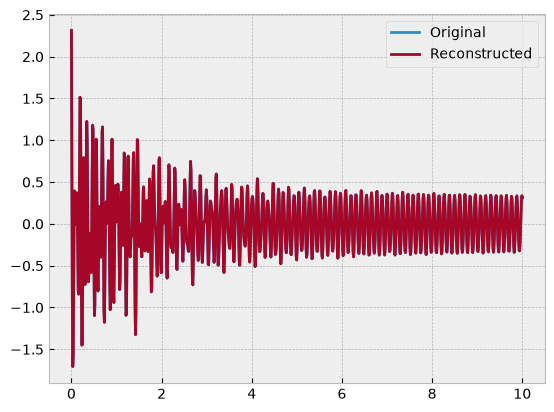

In [5]:
d_k = solve_more_linear_equations(layered_signal, z_k)

decay, freq = decay_and_freq(z_k, delta_t)
A_k, phase = amplitude_and_phase(d_k)

def reconstruct_signals(z_k, d_k, T=1000):
    """
    Using the acquired d_k and z_k, reconstruct the decays which made up the signal
    """

    assert len(z_k) == len(d_k)

    individual_signals = []

    for z, d in zip(z_k, d_k):

        signal = []

        for n in range(T):
            signal.append(d * z**n)

        individual_signals.append(signal)

    individual_signals = np.array(individual_signals, dtype=complex)
    reconstructed_fid = np.sum(individual_signals, axis=0)

    return individual_signals, reconstructed_fid

individual_signals, reconstructed_fid = reconstruct_signals(z_k, d_k)

error = np.max(np.abs(layered_signal - reconstructed_fid))
print(error)

plt.plot(time, np.real(layered_signal), label="Original", zorder =1)
plt.plot(time, np.real(reconstructed_fid), label="Reconstructed", zorder =2)
plt.legend()
plt.show()

This is excellent! Using only $10$ datapoints we have reconstructed the entire FID to an accuracy only off due to numerical error. The maximum difference between the 2 lines is $~ 3 \times 10^{-8}$. Plotting the original and reconstructed here it is hard to see what's going on but an overall absolute error on the order of $~10^{-5}$ is impressive. This would be an effective method for dealing with truncated signals. Now we have demonstrated the ptoential in an effective proof of concept, we can test how well this performs on more complex spectra, with more, and noisier signals.